# 02. Análisis exploratorio y estadística descriptiva


### Objetivo
Documentar propiedades a partir de tablas consolidadas.



## Preparación del entorno y lectura reproducible
El notebook busca el directorio `data/processed` generado en la etapa anterior, en su ausencia, permite ejecutarse con los dataset colocados junto al notebook o dentro de una carpeta indicada. No requiere los archivos originales.

Muestra cantidad de registros y cantidad de variables en los dataset trabajados.

In [23]:

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

FILES = [
    "column_quality.csv", "genre_frequency.csv", "key_checks.csv",
    "movie_genres.csv", "movies_consolidated.csv", "movies_without_ratings.csv",
    "movies_without_tags.csv", "post_validation.csv", "quality_overview.csv",
    "rating_aggregates_by_movie.csv", "rating_distribution.csv",
    "referential_integrity.csv", "tag_aggregates_by_movie.csv",
    "title_duplicates_exact.csv"
]


DATA_DIR_OVERRIDE = None
cwd = Path.cwd().resolve()
candidates = ([Path(DATA_DIR_OVERRIDE).expanduser().resolve()] if DATA_DIR_OVERRIDE else []) + [
    p / "data" / "processed" for p in (cwd, *cwd.parents)
] + [cwd, cwd / "data" / "processed", cwd / "archivos", Path("/mnt/data")]
DATA_DIR = next((p for p in candidates if p.is_dir() and all((p / f).is_file() for f in FILES)), None)
if DATA_DIR is None:
    raise FileNotFoundError("No se localizaron los dataset. Configura DATA_DIR_OVERRIDE con la carpeta donde se encuentran.")

tables = {Path(f).stem: pd.read_csv(DATA_DIR / f, low_memory=False) for f in FILES}
movies = tables["movies_consolidated"]
movie_genres = tables["movie_genres"]
rating_dist = tables["rating_distribution"].copy()
print("Directorio de datos:", DATA_DIR)
#print("Bases cargadas:", len(tables))
display(pd.DataFrame([{"archivo": f"{k}.csv", "registros": len(v), "variables": v.shape[1]} for k,v in tables.items()]))
assert len(tables) == 14
assert movies["movieId"].is_unique, "movies_consolidated debe tener una película por fila"
assert not movie_genres.duplicated(["movieId", "genre"]).any(), "Duplicación película-género"

Directorio de datos: /workspaces/Proyecto_Integrador_M1/data/processed


,archivo,registros,variables
0,column_quality.csv,14,7
1,genre_frequency.csv,19,3
2,key_checks.csv,4,5
3,movie_genres.csv,154170,2
4,movies_consolidated.csv,87585,20
5,movies_without_ratings.csv,3153,3
6,movies_without_tags.csv,36262,3
7,post_validation.csv,6,2
8,quality_overview.csv,4,8
9,rating_aggregates_by_movie.csv,84432,7


## 1. Entendimiento de los datos y registros relevantes
Las películas son entidades del catálogo, las puntuaciones son evaluaciones explícitas de usuarios y las etiquetas describen aportaciones textuales. Los identificadores de MovieLens, IMDb y TMDb son **identificadores **, no magnitudes, se consideran cualitativa nominal. `rating_count` mide cuántas evaluaciones recibió una película; `rating_mean` sólo existe si recibió al menos una. La ausencia de evaluaciones o etiquetas no equivale a una puntuación de cero ni a una opinión negativa.


In [24]:
# 2. COBERTURA, INTEGRIDAD Y REPRESENTATIVIDAD
q = tables["quality_overview"]
display(q)
for col in ["has_ratings", "has_tags", "has_imdb_id", "has_tmdb_id"]:
    if col in movies.columns:
        print(f"{col}: {movies[col].astype('boolean').mean()*100:.2f}% de las películas")
print("Calificaciones totales (tabla de frecuencias):", int(rating_dist["frequency"].sum()))
print("Películas distintas:", movies["movieId"].nunique())
print("Películas sin calificaciones:", int((movies["rating_count"] == 0).sum()))
print("Películas sin etiquetas:", int((movies["tag_application_count"] == 0).sum()))
print("Géneros distintos:", movie_genres["genre"].nunique())
print("Media global de evaluaciones por evento:",
      np.average(rating_dist["rating"], weights=rating_dist["frequency"]))
print("Media no ponderada de medias por película:", movies["rating_mean"].mean())
print("Las dos medias anteriores responden preguntas distintas: evento vs. película.")

ranking = movies.loc[movies["rating_count"] >= 100, ["movieId", "title_clean", "rating_count", "rating_mean", "tag_application_count"]]
print("Películas con mayor número de evaluaciones (sin inferir calidad):")
display(ranking.sort_values("rating_count", ascending=False).head(10))
print("Películas con media más elevada, restringiendo a >=100 evaluaciones:")
display(ranking.sort_values(["rating_mean", "rating_count"], ascending=False).head(10))

,dataset,records,columns,distinct_values_sum,full_row_duplicates,null_cells,completeness_pct,memory_mb
0,movies,87585,3,176765,0,0,100.0000,11.9166
1,ratings,32000204,4,26261913,0,0,100.0000,610.3556
2,tags,2000072,4,1499400,0,17,99.9998,145.2141
3,links,87585,3,262595,0,124,99.9528,1.8377


has_ratings: 96.40% de las películas
has_tags: 58.60% de las películas
has_imdb_id: 100.00% de las películas
has_tmdb_id: 99.86% de las películas
Calificaciones totales (tabla de frecuencias): 32000204
Películas distintas: 87585
Películas sin calificaciones: 3153
Películas sin etiquetas: 36262
Géneros distintos: 19
Media global de evaluaciones por evento: 3.5403956487277393
Media no ponderada de medias por película: 3.005082385038019
Las dos medias anteriores responden preguntas distintas: evento vs. película.
Películas con mayor número de evaluaciones (sin inferir calidad):


,movieId,title_clean,rating_count,rating_mean,tag_application_count
314,318,"Shawshank Redemption, The",102929,4.4046,4892
351,356,Forrest Gump,100296,4.0527,3581
292,296,Pulp Fiction,98409,4.1970,6697
2480,2571,"Matrix, The",93808,4.1564,5722
585,593,"Silence of the Lambs, The",90330,4.1484,3469
257,260,Star Wars: Episode IV - A New Hope,85010,4.0998,6519
2867,2959,Fight Club,77332,4.2288,5532
475,480,Jurassic Park,75233,3.6986,1510
522,527,Schindler's List,73849,4.2370,2059
4888,4993,"Lord of the Rings: The Fellowship of the Ring,...",73122,4.0921,2550


Películas con media más elevada, restringiendo a >=100 evaluaciones:


,movieId,title_clean,rating_count,rating_mean,tag_application_count
46252,171011,Planet Earth II,1956,4.4468,96
40985,159817,Planet Earth,2948,4.4444,103
46103,170705,Band of Brothers,2811,4.4265,234
314,318,"Shawshank Redemption, The",102929,4.4046,4892
46487,171495,Cosmos,615,4.3301,167
840,858,"Godfather, The",66440,4.3170,2310
61090,202439,Parasite,11670,4.3123,3052
50126,179135,Blue Planet II,1163,4.3001,74
59131,198185,Twin Peaks,1140,4.2987,146
68471,220528,Twelve Angry Men,449,4.2862,8


### Sesgos y límites de inferencia
- **Autoselección:** quienes califican películas no constituyen una muestra aleatoria de todas las personas ni de todos los espectadores.
- **Popularidad y supervivencia de actividad:** las películas con mayor exposición acumulan más observaciones; medias de títulos con pocos votos son menos estables.
- **Sesgo de cobertura:** los títulos sin evaluaciones participan en el catálogo, pero no en la distribución de notas observadas.
- **Granularidad y ponderación:** una media de medias por película pondera todos los títulos igual; la media global de evaluaciones pondera por número de eventos.
- **Géneros multilabel:** una película puede pertenecer a varios géneros; sumar las frecuencias de géneros no produce el total de películas.
- **No causalidad:** una correlación entre actividad y puntuación no demuestra que una variable genere la otra.

## 2. Clasificación de variables, escalas de medición y comparaciones permitidas

Se diferencian **tipo estadístico** y **escala**. Para una nominal son válidas igualdad, diferencias de proporciones y moda, no promedios. Una ordinal añade orden, mediana y cuantiles cuando se trata de puntuaciones ordenadas. La escala de intervalo permite diferencias numéricas pero no interpretaciones de tipo “el doble”; razón añade un cero absoluto y cocientes interpretables. Las puntuaciones `rating` son **ordinales discretas** en sentido estricto; analizar sus medias como *intervalo aproximado* constituye un supuesto práctico explícito. Una marca booleana es nominal dicotómica aunque se almacene como `bool`. Los identificadores numéricos siguen siendo nominales.

La desviación estándar, CV, asimetría, curtosis y Pearson no se aplican a IDs, textos ni indicadores categóricos. En las variables de conteo, un cero sí indica ausencia de actividad; en las medias de puntuación, cero no es un valor admisible en la escala.

In [25]:
# 3. DICCIONARIO ESTADÍSTICO DOCUMENTADO
metadata = {
"movieId": ("Cualitativa nominal", "Nominal", "ID de película", "Igualdad, unión, conteos de películas"),
"title_clean": ("Cualitativa nominal", "Nominal", "Título limpio", "Frecuencias y títulos duplicados"),
"title": ("Cualitativa nominal", "Nominal", "Título", "Frecuencias y títulos duplicados"),
"genres": ("Cualitativa nominal multilabel", "Nominal", "Lista de géneros", "Pertenencia y proporciones por categoría"),
"genres_original": ("Cualitativa nominal multilabel", "Nominal", "Géneros originales", "Comparación de categorías"),
"year": ("Cuantitativa discreta derivada", "Razón", "Año de estreno", "Tendencias temporales y agrupación por periodos"),
"genre": ("Cualitativa nominal", "Nominal", "Género individual", "Frecuencias y cobertura por género"),
"imdbId": ("Cualitativa nominal", "Nominal", "ID IMDb", "Unicidad y enlaces"),
"tmdbId": ("Cualitativa nominal", "Nominal", "ID TMDb", "Unicidad y enlaces"),
"rating": ("Cualitativa ordinal (valores discretos)", "Ordinal; intervalo aproximado para medias", "Puntos (0.5–5)", "Orden, frecuencias, cuartiles; media bajo supuesto"),
"rating_count": ("Cuantitativa discreta", "Razón", "Número de evaluaciones", "Diferencias, cocientes, cuantiles, dispersión"),
"rating_users": ("Cuantitativa discreta", "Razón", "Usuarios que evaluaron", "Diferencias, cocientes, dispersión"),
"rating_mean": ("Cuantitativa continua derivada", "Intervalo aproximado", "Puntos por película", "Diferencias; media/correlación con cautela"),
"rating_std": ("Cuantitativa continua derivada", "Razón (magnitud de dispersión)", "Puntos por película", "Comparación de dispersión; no aplica con n<2"),
"rating_min": ("Cuantitativa derivada discreta", "Ordinal", "Puntos", "Orden y comparación de extremos"),
"rating_max": ("Cuantitativa derivada discreta", "Ordinal", "Puntos", "Orden y comparación de extremos"),
"tag_application_count": ("Cuantitativa discreta", "Razón", "Etiquetas por película", "Frecuencias, cocientes y dispersión"),
"non_null_tag_count": ("Cuantitativa discreta", "Razón", "Etiquetas con texto", "Frecuencias, cocientes y dispersión"),
"distinct_tags": ("Cuantitativa discreta", "Razón", "Etiquetas únicas por película", "Conteos y comparación de diversidad textual"),
"tag_users": ("Cuantitativa discreta", "Razón", "Usuarios con etiquetas", "Conteos y comparaciones"),
"has_ratings": ("Cualitativa nominal dicotómica", "Nominal", "Sí/no", "Proporciones y tablas cruzadas"),
"has_tags": ("Cualitativa nominal dicotómica", "Nominal", "Sí/no", "Proporciones y tablas cruzadas"),
"has_imdb_id": ("Cualitativa nominal dicotómica", "Nominal", "Sí/no", "Cobertura de identificadores"),
"has_tmdb_id": ("Cualitativa nominal dicotómica", "Nominal", "Sí/no", "Cobertura de identificadores"),
}
dictionary = pd.DataFrame([{
    "variable": c, "tipo_estadístico": metadata.get(c, ("Revisar", "Revisar", "", ""))[0],
    "escala": metadata.get(c, ("Revisar", "Revisar", "", ""))[1],
    "unidad/significado": metadata.get(c, ("", "", "Revisar", ""))[2],
    "comparaciones_permitidas": metadata.get(c, ("", "", "", "Revisar"))[3],
    "tipo_python": str(movies[c].dtype)
} for c in movies.columns])
display(dictionary)
assert not dictionary["tipo_estadístico"].eq("Revisar").any(), "Clasifica cualquier columna nueva antes de analizarla"

,variable,tipo_estadístico,escala,unidad/significado,comparaciones_permitidas,tipo_python
0,movieId,Cualitativa nominal,Nominal,ID de película,"Igualdad, unión, conteos de películas",int64
1,title_clean,Cualitativa nominal,Nominal,Título limpio,Frecuencias y títulos duplicados,str
2,year,Cuantitativa discreta derivada,Razón,Año de estreno,Tendencias temporales y agrupación por periodos,float64
3,genres,Cualitativa nominal multilabel,Nominal,Lista de géneros,Pertenencia y proporciones por categoría,str
4,imdbId,Cualitativa nominal,Nominal,ID IMDb,Unicidad y enlaces,int64
5,tmdbId,Cualitativa nominal,Nominal,ID TMDb,Unicidad y enlaces,float64
6,rating_count,Cuantitativa discreta,Razón,Número de evaluaciones,"Diferencias, cocientes, cuantiles, dispersión",int64
7,rating_mean,Cuantitativa continua derivada,Intervalo aproximado,Puntos por película,Diferencias; media/correlación con cautela,float64
8,rating_std,Cuantitativa continua derivada,Razón (magnitud de dispersión),Puntos por película,Comparación de dispersión; no aplica con n<2,float64
9,rating_min,Cuantitativa derivada discreta,Ordinal,Puntos,Orden y comparación de extremos,float64


## 3. Distribuciones de frecuencia
Para variables nominales se presentan frecuencias absolutas y relativas. Para conteos cuantitativos se incluyen intervalos interpretables definidos de antemano.

In [26]:
# 4. FRECUENCIAS CATEGÓRICAS Y ORDINALES
print("Distribución completa de calificaciones por evento:")
rd = rating_dist.sort_values("rating").copy()
rd["porcentaje_recalculado"] = rd["frequency"] / rd["frequency"].sum() * 100
display(rd)
print("Frecuencia de géneros: una película puede aparecer en varios géneros")
g = movie_genres.groupby("genre", dropna=False)["movieId"].nunique().sort_values(ascending=False).rename("peliculas").reset_index()
g["porcentaje_catalogo"] = 100 * g["peliculas"] / movies["movieId"].nunique()
display(g)
for flag in ["has_ratings", "has_tags", "has_imdb_id", "has_tmdb_id"]:
    d = movies[flag].value_counts(dropna=False).rename_axis(flag).reset_index(name="frecuencia")
    d["porcentaje"] = 100 * d["frecuencia"] / len(movies)
    print(flag)
    display(d)

bins = [-0.1, 0, 1, 5, 20, 100, 1000, np.inf]
labels = ["0", "1", "2–5", "6–20", "21–100", "101–1000", ">1000"]
for field in ["rating_count", "tag_application_count"]:
    d = pd.cut(movies[field], bins=bins, labels=labels).value_counts(sort=False)
    display(pd.DataFrame({"variable": field, "intervalo": d.index.astype(str), "frecuencia": d.values,
                          "porcentaje": d.values / len(movies) * 100}))
print("La suma de porcentajes por género puede superar 100% por clasificación múltiple.")

Distribución completa de calificaciones por evento:


,rating,frequency,percentage,porcentaje_recalculado
0,0.5000,525132,1.6410,1.6410
1,1.0000,946675,2.9583,2.9583
2,1.5000,531063,1.6596,1.6596
3,2.0000,2028622,6.3394,6.3394
4,2.5000,1685386,5.2668,5.2668
5,3.0000,6054990,18.9217,18.9217
6,3.5000,4290105,13.4065,13.4065
7,4.0000,8367654,26.1488,26.1488
8,4.5000,2974000,9.2937,9.2937
9,5.0000,4596577,14.3642,14.3642


Frecuencia de géneros: una película puede aparecer en varios géneros


,genre,peliculas,porcentaje_catalogo
0,Drama,41255,47.1028
1,Comedy,23124,26.4018
2,Thriller,11823,13.4989
3,Romance,10369,11.8388
4,Action,9668,11.0384
5,Documentary,9363,10.6902
6,Horror,8654,9.8807
7,Crime,6976,7.9648
8,Adventure,5402,6.1677
9,Sci-Fi,4907,5.6026


has_ratings


,has_ratings,frecuencia,porcentaje
0,True,84432,96.4001
1,False,3153,3.5999


... (5 outputs left out)

,has_tmdb_id,frecuencia,porcentaje
0,True,87461,99.8584
1,False,124,0.1416


,variable,intervalo,frecuencia,porcentaje
0,rating_count,0,3153,3.5999
1,rating_count,1,18607,21.2445
2,rating_count,2–5,25420,29.0232
3,rating_count,6–20,17547,20.0343
4,rating_count,21–100,10713,12.2315
5,rating_count,101–1000,7750,8.8485
6,rating_count,>1000,4395,5.0180


,variable,intervalo,frecuencia,porcentaje
0,tag_application_count,0,36262,41.4021
1,tag_application_count,1,7682,8.7709
2,tag_application_count,2–5,18056,20.6154
3,tag_application_count,6–20,14519,16.5770
4,tag_application_count,21–100,7193,8.2126
5,tag_application_count,101–1000,3630,4.1445
6,tag_application_count,>1000,243,0.2774


La suma de porcentajes por género puede superar 100% por clasificación múltiple.


## 4. Medidas centrales, de variabilidad y robustez

Para conteos (escala de razón) se calculan media, mediana, moda, varianza **muestral** (`ddof=1`), desviación estándar muestral, cuartiles, rango intercuartílico `Q3−Q1`, y coeficiente de variación `DE/media` cuando la media es positiva. El **CV** carece de sentido para identificadores, medias de calificaciones en escala sin cero absoluto y variables cuyo promedio sea cero. 

El IQR concentra la amplitud del 50% central de observaciones; es relativamente resistente a extremos. Como indicador de sensibilidad se compara la media original con una media recortada simétricamente al 5% y con la mediana. La media recortada **no sustituye ni elimina** registros originales.

In [27]:
# 5. DESCRIPTIVOS ROBUSTOS PARA CONTEOS A NIVEL PELÍCULA
def trimmed_mean(x, proportion=0.05):
    v = np.sort(pd.to_numeric(pd.Series(x), errors="coerce").dropna().to_numpy(dtype=float))
    k = int(len(v) * proportion)
    return float(v[k: len(v)-k].mean()) if len(v) > 2*k else np.nan

def descriptive(x, name, cv=True):
    s = pd.to_numeric(pd.Series(x), errors="coerce").dropna()
    if s.empty: return {"variable": name, "n": 0}
    q1, q3 = s.quantile([0.25, 0.75]); mu = s.mean(); sd = s.std(ddof=1)
    modes = s.mode()
    return {"variable": name, "n": int(len(s)), "media": mu, "mediana": s.median(),
            "moda": modes.iloc[0] if len(modes) else np.nan,
            "modas_totales": len(modes), "varianza_muestral": s.var(ddof=1),
            "desviacion_muestral": sd, "q1": q1, "q3": q3, "IQR": q3-q1,
            "mínimo": s.min(), "máximo": s.max(),
            "CV_pct": 100*sd/mu if cv and mu>0 else np.nan,
            "media_recortada_5pct": trimmed_mean(s),
            "cambio_media_recorte_pct": 100*(trimmed_mean(s)-mu)/mu if mu != 0 else np.nan}

count_vars = ["rating_count", "rating_users", "tag_application_count", "non_null_tag_count", "distinct_tags", "tag_users"]
count_stats = pd.DataFrame([descriptive(movies[c],c) for c in count_vars])
display(count_stats.set_index("variable").T)
print("CV: cuanto mayor es, más dispersión relativa en una misma medida de razón; no existe umbral universal.")
print("La comparación media/mediana y el cambio por recorte diagnostican sensibilidad, no prueban una distribución.")

variable,rating_count,rating_users,tag_application_count,non_null_tag_count,distinct_tags,tag_users
n,"87,585.0000","87,585.0000","87,585.0000","87,585.0000","87,585.0000","87,585.0000"
media,365.3617,365.3617,22.8358,22.8356,12.4088,3.9966
mediana,5.0000,5.0000,1.0000,1.0000,1.0000,1.0000
moda,1.0000,1.0000,0.0000,0.0000,0.0000,0.0000
modas_totales,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
varianza_muestral,"6,483,784.1555","6,483,784.1555","15,545.3252","15,545.2835","1,991.1156",400.9613
desviacion_muestral,"2,546.3276","2,546.3276",124.6809,124.6807,44.6219,20.0240
q1,2.0000,2.0000,0.0000,0.0000,0.0000,0.0000
q3,23.0000,23.0000,7.0000,7.0000,7.0000,2.0000
IQR,21.0000,21.0000,7.0000,7.0000,7.0000,2.0000


CV: cuanto mayor es, más dispersión relativa en una misma medida de razón; no existe umbral universal.
La comparación media/mediana y el cambio por recorte diagnostican sensibilidad, no prueban una distribución.


### Descriptivos de las calificaciones y distinción entre unidades
La escala de calificación es discreta y ordenada. La media y la varianza se muestran bajo la convención habitual de tratar los saltos de 0.5 como intervalos comparables. Los descriptivos **por evento** usan frecuencias ponderadas; los descriptivos **por película** usan una observación por título con evaluaciones. No debe interpretarse el CV de estas puntuaciones como razón relativa.

In [28]:
# 6. ESTADÍSTICA PONDERADA SIN EXPANDIR LOS EVENTOS
def weighted_quantile(values, weights, p):
    idx = np.argsort(values)
    v = np.asarray(values, dtype=float)[idx]
    w = np.asarray(weights, dtype=np.int64)[idx]
    return v[min(np.searchsorted(np.cumsum(w), p*w.sum(), side="left"), len(v)-1)]

v = rd["rating"].to_numpy(dtype=float)
w = rd["frequency"].to_numpy(dtype=np.int64)
N = int(w.sum()); mean_event = np.average(v, weights=w)
var_event = np.dot(w, (v-mean_event)**2) / (N-1) if N>1 else np.nan
rating_event_stats = pd.DataFrame([{
    "n_eventos": N, "media": mean_event,
    "mediana": weighted_quantile(v,w,0.5), "moda": v[np.argmax(w)],
    "varianza_muestral": var_event, "desviacion_muestral": np.sqrt(var_event),
    "q1": weighted_quantile(v,w,0.25), "q3": weighted_quantile(v,w,0.75),
    "IQR": weighted_quantile(v,w,0.75)-weighted_quantile(v,w,0.25)
}])
print("Distribución de calificaciones por EVENTO")
display(rating_event_stats)
print("Distribución de medias por PELÍCULA, sólo títulos evaluados")
movie_rating_stats = pd.DataFrame([descriptive(movies.loc[movies["rating_count"]>0,"rating_mean"], "rating_mean", cv=False),
                                    descriptive(movies.loc[movies["rating_count"]>=100,"rating_mean"], "rating_mean (>=100 votos)", cv=False)])
display(movie_rating_stats.set_index("variable").T)
print("La varianza de las medias por película NO equivale a la varianza entre evaluaciones individuales.")

Distribución de calificaciones por EVENTO


,n_eventos,media,mediana,moda,varianza_muestral,desviacion_muestral,q1,q3,IQR
0,32000204,3.5404,3.5000,4.0000,1.1215,1.0590,3.0000,4.0000,1.0000


Distribución de medias por PELÍCULA, sólo títulos evaluados


variable,rating_mean,rating_mean (>=100 votos)
n,"84,432.0000","12,191.0000"
media,3.0051,3.2959
mediana,3.0714,3.3672
moda,3.0000,3.5000
modas_totales,1.0000,1.0000
varianza_muestral,0.6429,0.2301
desviacion_muestral,0.8018,0.4797
q1,2.5435,3.0137
q3,3.5000,3.6528
IQR,0.9565,0.6391


La varianza de las medias por película NO equivale a la varianza entre evaluaciones individuales.


## 5. Forma de distribución: asimetría y curtosis
La asimetría positiva indica cola hacia la derecha y la negativa, hacia la izquierda. Cuando la curtosisi reporta valores altos pueden reflejar colas pesadas o valores extremos, no necesariamente una forma normal.

In [29]:
# 7. FORMA ESTADÍSTICA
shape_rows = []
for c in count_vars + ["rating_mean"]:
    s = pd.to_numeric(movies[c], errors="coerce").dropna()
    if c == "rating_mean": s = s[movies.loc[s.index, "rating_count"] > 0]
    skew = s.skew() if len(s)>2 and s.nunique()>2 else np.nan
    kurt = s.kurt() if len(s)>3 and s.nunique()>3 else np.nan
    shape_rows.append({"variable":c,"n":len(s),"pct_ceros":100*(s==0).mean(),
                       "asimetria_fisher":skew,"orientacion": ("derecha" if skew>0 else "izquierda" if skew<0 else "simétrica aprox.") if pd.notna(skew) else "no evaluable",
                       "exceso_curtosis_fisher":kurt})
shape = pd.DataFrame(shape_rows)
display(shape)
# Momentos de la distribución de calificaciones individuales a partir de frecuencias.
mu = mean_event
m2 = np.average((v-mu)**2, weights=w)
m3 = np.average((v-mu)**3, weights=w)
m4 = np.average((v-mu)**4, weights=w)
print("Asimetría ponderada de calificaciones (momento poblacional):", m3/m2**1.5 if m2>0 else np.nan)
print("Exceso de curtosis ponderado de calificaciones (momento poblacional):", m4/m2**2-3 if m2>0 else np.nan)


,variable,n,pct_ceros,asimetria_fisher,orientacion,exceso_curtosis_fisher
0,rating_count,87585,3.5999,15.9020,derecha,360.2967
1,rating_users,87585,3.5999,15.9020,derecha,360.2967
2,tag_application_count,87585,41.4021,18.5215,derecha,592.1917
3,non_null_tag_count,87585,41.4021,18.5215,derecha,592.1949
4,distinct_tags,87585,41.4021,7.8836,derecha,82.2088
5,tag_users,87585,41.4021,24.6268,derecha,"1,469.3666"
6,rating_mean,84432,0.0000,-0.6101,izquierda,1.0645


Asimetría ponderada de calificaciones (momento poblacional): -0.7190238734384279
Exceso de curtosis ponderado de calificaciones (momento poblacional): 0.25944395897200456


## 6. Valores atípicos: detección, investigación y decisión

Se aplica la regla de Tukey `[Q1−1.5·RIQ, Q3+1.5·RIQ]`. Para datos muy concentrados en cero, RIQ puede ser cero y señalar muchas observaciones válidas. También se revisan los percentiles 95, 99 y 99.9. No se eliminan automáticamente películas populares ni títulos con pocas evaluaciones: la popularidad extrema puede ser genuina. Para puntuaciones individuales, 0.5 y 5 son límites válidos, no errores por sí mismos.


In [30]:
# 8. DETECCIÓN DE ATÍPICOS EN VARIABLES DE ACTIVIDAD
outlier_rows=[]
for c in count_vars:
    s=movies[c].dropna()
    q1,q3=s.quantile([.25,.75]); iqr=q3-q1; lo=max(0, q1-1.5*iqr); hi=q3+1.5*iqr
    outlier_rows.append({"variable":c,"q1":q1,"q3":q3,"IQR":iqr,
                         "limite_inferior":lo,"limite_superior":hi,"n_fuera":int(((s<lo)|(s>hi)).sum()),
                         "pct_fuera":100*((s<lo)|(s>hi)).mean(),
                         "p95":s.quantile(.95),"p99":s.quantile(.99),"p999":s.quantile(.999),
                         "maximo":s.max(),"IQR_cero":iqr==0})
outliers=pd.DataFrame(outlier_rows)
display(outliers)
print("Casos de máxima actividad para investigar; no se excluyen:")
display(movies.nlargest(12,"rating_count")[["movieId","title_clean","rating_count","rating_mean","tag_application_count"]])
print("Casos con >=100 evaluaciones y dispersión interna más alta:")
display(movies.loc[movies["rating_count"]>=100].nlargest(10,"rating_std")[["movieId","title_clean","rating_count","rating_mean","rating_std"]])

# Comprobar reglas de negocio antes de considerar un dato anómalo como error.
checks = {
    "conteos_negativos": int((movies[count_vars]<0).sum().sum()),
    "rating_mean_fuera_escala": int(((movies["rating_mean"].notna()) & ~movies["rating_mean"].between(0.5,5)).sum()),
    "media_sin_votos": int(((movies["rating_count"]==0)&movies["rating_mean"].notna()).sum()),
    "std_sin_al_menos_dos_votos": int(((movies["rating_count"]<2)&movies["rating_std"].notna()).sum()),
    "usuarios_mayores_que_calificaciones": int((movies["rating_users"]>movies["rating_count"]).sum()),
}
display(pd.Series(checks, name="incidencias"))

,variable,q1,q3,IQR,limite_inferior,limite_superior,n_fuera,pct_fuera,p95,p99,p999,maximo,IQR_cero
0,rating_count,2.0000,23.0000,21.0000,0,54.5000,15437,17.6252,"1,006.6000","8,877.8000","37,690.3440",102929,False
1,rating_users,2.0000,23.0000,21.0000,0,54.5000,15437,17.6252,"1,006.6000","8,877.8000","37,690.3440",102929,False
2,tag_application_count,0.0000,7.0000,7.0000,0,17.5000,12266,14.0047,85.0000,436.0000,"1,674.7280",6697,False
3,non_null_tag_count,0.0000,7.0000,7.0000,0,17.5000,12265,14.0035,85.0000,436.0000,"1,674.7280",6697,False
4,distinct_tags,0.0000,7.0000,7.0000,0,17.5000,10647,12.1562,50.0000,243.1600,519.0000,1111,False
5,tag_users,0.0000,2.0000,2.0000,0,5.0000,9008,10.2849,14.0000,71.0000,256.6640,2007,False


Casos de máxima actividad para investigar; no se excluyen:


,movieId,title_clean,rating_count,rating_mean,tag_application_count
314,318,"Shawshank Redemption, The",102929,4.4046,4892
351,356,Forrest Gump,100296,4.0527,3581
292,296,Pulp Fiction,98409,4.1970,6697
2480,2571,"Matrix, The",93808,4.1564,5722
585,593,"Silence of the Lambs, The",90330,4.1484,3469
257,260,Star Wars: Episode IV - A New Hope,85010,4.0998,6519
2867,2959,Fight Club,77332,4.2288,5532
475,480,Jurassic Park,75233,3.6986,1510
522,527,Schindler's List,73849,4.2370,2059
4888,4993,"Lord of the Rings: The Fellowship of the Ring,...",73122,4.0921,2550


Casos con >=100 evaluaciones y dispersión interna más alta:


,movieId,title_clean,rating_count,rating_mean,rating_std
1277,1311,Santa with Muscles,163,2.5521,1.7075
14392,74754,"Room, The",1179,2.4822,1.6428
21478,110603,God's Not Dead,241,2.4108,1.6277
12322,59295,Expelled: No Intelligence Allowed,166,2.0964,1.5963
11344,50703,"Secret, The",204,2.3186,1.5738
1382,1421,Grateful Dead,190,3.0421,1.5654
29196,133123,Barbie as The Princess & the Pauper,142,3.2817,1.5419
1347,1383,Adrenalin: Fear the Rush,149,2.2517,1.5264
52263,183589,Fifty Shades Freed,394,2.4987,1.5206
13101,66659,Tyler Perry's Madea Goes to Jail,142,2.5634,1.5134


conteos_negativos                      0
rating_mean_fuera_escala               0
media_sin_votos                        0
std_sin_al_menos_dos_votos             0
usuarios_mayores_que_calificaciones    0
Name: incidencias, dtype: int64

## 7. Calidad de datos y patrones de faltantes
Se evalúa número y porcentaje de nulos por variable. La tabla `column_quality` proviene de las fuentes **anteriores** a la consolidación y se muestra aparte: no se debe comparar directamente su denominador con el consolidado.


In [31]:
# 9. FALTANTES POR COLUMNA Y PATRONES CONJUNTOS
missing = pd.DataFrame({"variable":movies.columns,"faltantes":movies.isna().sum().values,
                        "pct_faltantes":movies.isna().mean().values*100,
                        "dtype":movies.dtypes.astype(str).values}).sort_values("faltantes",ascending=False)
display(missing)
print("Diagnóstico de faltantes estructurales en medidas de rating:")
display(pd.crosstab(movies["rating_count"].clip(upper=2).map({0:"0 evaluaciones",1:"1 evaluación",2:"2+ evaluaciones"}),
                    movies["rating_std"].isna(), rownames=["actividad"],colnames=["rating_std ausente"], margins=True))
print("Patrones combinados de ausencia: IDs externos y medias de rating")
cols = ["imdbId","tmdbId","rating_mean","rating_std"]
patterns = movies[cols].isna().rename(columns=lambda c:c+"_nulo")
display(patterns.value_counts(dropna=False).rename("peliculas").reset_index().head(20))
print("Comparación cobertura de TMDb según actividad:")
display(pd.crosstab(movies["has_ratings"], movies["tmdbId"].isna(), normalize="index"))
print("Informe de calidad preintegración:")
display(tables["column_quality"])
print("Resultados de validación y referencial:")
display(tables["post_validation"])
display(tables["referential_integrity"])

,variable,faltantes,pct_faltantes,dtype
8,rating_std,21760,24.8444,float64
10,rating_max,3153,3.5999,float64
7,rating_mean,3153,3.5999,float64
9,rating_min,3153,3.5999,float64
2,year,617,0.7045,float64
5,tmdbId,124,0.1416,float64
1,title_clean,1,0.0011,str
0,movieId,0,0.0000,int64
3,genres,0,0.0000,str
4,imdbId,0,0.0000,int64


Diagnóstico de faltantes estructurales en medidas de rating:


rating_std ausente,False,True,All
actividad,,,
0 evaluaciones,0,3153,3153
1 evaluación,0,18607,18607
2+ evaluaciones,65825,0,65825
All,65825,21760,87585


Patrones combinados de ausencia: IDs externos y medias de rating


,imdbId_nulo,tmdbId_nulo,rating_mean_nulo,rating_std_nulo,peliculas
0,False,False,False,False,65735
1,False,False,False,True,18575
2,False,False,True,True,3151
3,False,True,False,False,90
4,False,True,False,True,32
5,False,True,True,True,2


Comparación cobertura de TMDb según actividad:


... (2 outputs left out)

,dataset,column,dtype,non_null,nulls,null_pct,unique_non_null
0,movies,movieId,int32,87585,0,0.0000,87585
1,movies,title,string,87585,0,0.0000,87382
2,movies,genres,string,87585,0,0.0000,1798
3,ratings,userId,int32,32000204,0,0.0000,200948
4,ratings,movieId,int32,32000204,0,0.0000,84432
5,ratings,rating,float32,32000204,0,0.0000,10
6,ratings,timestamp,int64,32000204,0,0.0000,25976523
7,tags,userId,int32,2000072,0,0.0000,15848
8,tags,movieId,int32,2000072,0,0.0000,51323
9,tags,tag,string,2000055,17,0.0008,140979


Resultados de validación y referencial:


,test,passed
0,movieId único en movies_consolidated,True
1,Se preservó el total de películas,True
2,Combinación movieId-genre única,True
3,Géneros vinculados a películas existentes,True
4,Agregado de ratings reconcilia con ratings ori...,True
5,Agregado de tags reconcilia con tags original,True


,child_table,distinct_movie_ids,ids_found_in_movies,orphan_movie_ids
0,ratings,84432,84432,0
1,tags,51323,51323,0
2,links,87585,87585,0


## 8. Relaciones bivariadas, asociaciones y correlaciones

Se comparan métricas por película, nunca IDs. Las variables `rating_count` y `rating_users` pueden ser prácticamente equivalentes por diseño: una correlación elevada sería estructural, no un hallazgo independiente. Se omiten variables con varianza cero.

Las medias de calificación se correlacionan sólo entre películas con evaluaciones y se repite el análisis restringiendo a **≥100 evaluaciones**, porque una nota calculada con un voto tiene incertidumbre muy distinta de otra calculada con miles. Los resultados son descriptivos, no inferenciales ni causales.

In [32]:
# 10. CORRELACIONES DE VARIABLES DE ACTIVIDAD Y PUNTUACIÓN
variables = ["rating_count","tag_application_count","distinct_tags","tag_users","rating_mean","rating_std"]
full = movies.loc[movies["rating_count"]>0,variables].copy()
restricted = movies.loc[movies["rating_count"]>=100,variables].copy()
for name, subset in [("Películas con al menos 1 evaluación",full),("Películas con al menos 100 evaluaciones",restricted)]:
    print("\n",name,"n=",len(subset))
    print("Pearson:")
    display(subset.corr(method="pearson"))
    print("Spearman:")
    display(subset.corr(method="spearman"))

# N de observaciones completas para pares seleccionados (correlación sin n puede engañar).
pairs = [("rating_count","tag_application_count"),("rating_count","rating_mean"),
         ("rating_mean","rating_std"),("tag_application_count","distinct_tags")]
correlation_rows=[]
for filt, sub in [("n>=1",full),("n>=100",restricted)]:
    for a,b in pairs:
        z=sub[[a,b]].dropna()
        correlation_rows.append({"muestra":filt,"variable_x":a,"variable_y":b,"n_pares":len(z),
                                 "pearson":z[a].corr(z[b],method="pearson"),
                                 "spearman":z[a].corr(z[b],method="spearman")})
correlation_summary=pd.DataFrame(correlation_rows)
display(correlation_summary)
print("Correlaciones sensibles al tamaño muestral, a la selección de películas y a la distribución sesgada.")


 Películas con al menos 1 evaluación n= 84432
Pearson:


,rating_count,tag_application_count,distinct_tags,tag_users,rating_mean,rating_std
rating_count,1.0000,0.7689,0.5287,0.8381,0.0976,-0.0045
tag_application_count,0.7689,1.0000,0.7637,0.9332,0.1098,-0.0040
distinct_tags,0.5287,0.7637,1.0000,0.5987,0.1082,0.0045
tag_users,0.8381,0.9332,0.5987,1.0000,0.1198,-0.0056
rating_mean,0.0976,0.1098,0.1082,0.1198,1.0000,-0.1683
rating_std,-0.0045,-0.0040,0.0045,-0.0056,-0.1683,1.0000


Spearman:


,rating_count,tag_application_count,distinct_tags,tag_users,rating_mean,rating_std
rating_count,1.0000,0.6802,0.6737,0.7107,0.1549,0.1801
tag_application_count,0.6802,1.0000,0.9988,0.9570,0.1400,0.0579
distinct_tags,0.6737,0.9988,1.0000,0.9506,0.1371,0.0570
tag_users,0.7107,0.9570,0.9506,1.0000,0.1497,0.0580
rating_mean,0.1549,0.1400,0.1371,0.1497,1.0000,-0.2402
rating_std,0.1801,0.0579,0.0570,0.0580,-0.2402,1.0000



 Películas con al menos 100 evaluaciones n= 12191
Pearson:


,rating_count,tag_application_count,distinct_tags,tag_users,rating_mean,rating_std
rating_count,1.0000,0.7400,0.4676,0.8150,0.2135,-0.0875
tag_application_count,0.7400,1.0000,0.7269,0.9271,0.2500,-0.0965
distinct_tags,0.4676,0.7269,1.0000,0.5343,0.1751,-0.0564
tag_users,0.8150,0.9271,0.5343,1.0000,0.2768,-0.1168
rating_mean,0.2135,0.2500,0.1751,0.2768,1.0000,-0.5045
rating_std,-0.0875,-0.0965,-0.0564,-0.1168,-0.5045,1.0000


Spearman:


,rating_count,tag_application_count,distinct_tags,tag_users,rating_mean,rating_std
rating_count,1.0000,0.6233,0.5521,0.7520,0.1913,-0.1040
tag_application_count,0.6233,1.0000,0.9675,0.8534,0.3028,-0.1459
distinct_tags,0.5521,0.9675,1.0000,0.7518,0.2713,-0.1330
tag_users,0.7520,0.8534,0.7518,1.0000,0.3577,-0.1905
rating_mean,0.1913,0.3028,0.2713,0.3577,1.0000,-0.5135
rating_std,-0.1040,-0.1459,-0.1330,-0.1905,-0.5135,1.0000


,muestra,variable_x,variable_y,n_pares,pearson,spearman
0,n>=1,rating_count,tag_application_count,84432,0.7689,0.6802
1,n>=1,rating_count,rating_mean,84432,0.0976,0.1549
2,n>=1,rating_mean,rating_std,65825,-0.1683,-0.2402
3,n>=1,tag_application_count,distinct_tags,84432,0.7637,0.9988
4,n>=100,rating_count,tag_application_count,12191,0.7400,0.6233
5,n>=100,rating_count,rating_mean,12191,0.2135,0.1913
6,n>=100,rating_mean,rating_std,12191,-0.5045,-0.5135
7,n>=100,tag_application_count,distinct_tags,12191,0.7269,0.9675


Correlaciones sensibles al tamaño muestral, a la selección de películas y a la distribución sesgada.


### Asociación entre categorías y comportamiento por género
Se compara la cobertura de evaluaciones entre géneros mediante tasas. Para medias de puntuación, cada película se cuenta una vez **dentro de cada género** y se restringe a títulos con ≥100 votos; como las categorías se superponen, las filas no representan grupos independientes. Se muestra también mediana para robustez.

In [33]:
# 11. ASOCIACIONES CATEGÓRICAS Y COMPARACIÓN MULTILABEL
joint = pd.crosstab(movies["has_ratings"],movies["has_tags"],margins=True)
display(joint)
display(pd.crosstab(movies["has_ratings"],movies["has_tags"],normalize="index")*100)
per_genre = movie_genres.merge(
    movies[["movieId","rating_count","rating_mean","has_ratings","tag_application_count"]],
    on="movieId",how="left",validate="many_to_many")
genre_summary = per_genre.groupby("genre").agg(
    peliculas=("movieId","nunique"),
    pct_con_evaluaciones=("has_ratings",lambda x:100*x.mean()),
    mediana_evaluaciones=("rating_count","median"),
    media_evaluaciones=("rating_count","mean"),
    mediana_etiquetas=("tag_application_count","median"))
eligible = per_genre.loc[per_genre["rating_count"]>=100]
rating_genre = eligible.groupby("genre").agg(
    peliculas_con_100_votos=("movieId","nunique"),
    media_puntuacion_por_pelicula=("rating_mean","mean"),
    mediana_puntuacion_por_pelicula=("rating_mean","median"))
genre_summary=genre_summary.join(rating_genre)
display(genre_summary.sort_values("peliculas",ascending=False))
print("Porcentaje sobre catálogo por género NO suma 100%; pertenencias múltiples.")
print("No se calculan correlaciones entre nombres de géneros e IDs numéricos.")

has_tags,False,True,All
has_ratings,,,
False,0,3153,3153
True,36262,48170,84432
All,36262,51323,87585


has_tags,False,True
has_ratings,,
False,0.0000,100.0000
True,42.9482,57.0518


,peliculas,pct_con_evaluaciones,mediana_evaluaciones,media_evaluaciones,mediana_etiquetas,peliculas_con_100_votos,media_puntuacion_por_pelicula,mediana_puntuacion_por_pelicula
genre,,,,,,,,
Drama,41255,96.2477,4.0000,340.0502,2.0000,5819,3.4516,3.5112
Comedy,23124,97.0766,6.0000,484.6448,2.0000,4231,3.1927,3.2460
Thriller,11823,97.7332,7.0000,734.1169,3.0000,2498,3.2274,3.2517
Romance,10369,96.9042,6.0000,532.8011,2.0000,1919,3.3585,3.4161
Action,9668,96.1523,8.0000,999.7117,3.0000,2111,3.1522,3.1899
Documentary,9363,97.2231,3.0000,45.6427,1.0000,547,3.6476,3.7202
Horror,8654,97.8507,6.0000,287.9957,3.0000,1357,2.9776,3.0322
Crime,6976,96.1009,7.0000,770.2195,3.0000,1469,3.3541,3.4105
Adventure,5402,95.4461,10.0000,"1,405.1318",4.0000,1458,3.2091,3.2628


Porcentaje sobre catálogo por género NO suma 100%; pertenencias múltiples.
No se calculan correlaciones entre nombres de géneros e IDs numéricos.


## 9. Conclusiones
Se redacta un resumen a partir de lo calculado.

In [34]:
# 12. SÍNTESIS AUTOMÁTICA DE RESULTADOS
n_movies=len(movies)
n_rated=int(movies["has_ratings"].sum())
n_tagged=int(movies["has_tags"].sum())
median_v=float(movies["rating_count"].median())
mean_v=float(movies["rating_count"].mean())
mode_rating=float(rd.loc[rd["frequency"].idxmax(),"rating"])
rank_corr=correlation_summary.query('muestra == "n>=100" and variable_x == "rating_count" and variable_y == "rating_mean"')["spearman"].iloc[0]
most_genre=genre_summary["peliculas"].idxmax()
print("¿QUÉ REPRESENTAN LOS REGISTROS MÁS IMPORTANTES?")
print(f"• Catálogo: {n_movies:,} películas, {n_rated:,} con evaluaciones y {n_tagged:,} con etiquetas.")
print(f"• Distribución: {N:,} eventos de rating; puntuación modal {mode_rating:g} y media por evento {mean_event:.3f}.")
print("• Las películas con más eventos documentan concentración de actividad; sin eventos, no se puede estimar opinión.")
print("\n¿QUÉ VARIABLES SE TIENEN?")
print(f"• {len(movies.columns)} columnas de catálogo: identificadores y etiquetas nominales, flags dicotómicos, conteos de razón y resúmenes de rating.")
print("• Géneros: variable nominal multilabel; rating original: ordinal discreta (intervalo aproximado para promedios).")
print("\n¿QUÉ PATRONES SE DETECTARON?")
print(f"• Votos por película: media {mean_v:.2f} y mediana {median_v:.2f}; la diferencia indica concentración de actividad." )
print(f"• Género con mayor presencia: {most_genre} ({int(genre_summary.loc[most_genre,'peliculas']):,} películas).")
print(f"• Asociación monotónica votos–media con >=100 votos (Spearman): {rank_corr:.3f}.")
print(f"• Se localizaron nulos en {int((missing['faltantes']>0).sum())} columnas, con diagnóstico de ausencia estructural y cobertura.")
print("• Los outliers se conservan, sujetos a revisión de reglas de negocio; no hay recodificación automática.")
print("\nLIMITACIONES")
print("• Sin datos originales de usuario y fecha: no se evalúan efectos temporales, cohortes o dependencia intrausuario.")
print("• Un género no es exclusivo y una correlación no demuestra causalidad.")

¿QUÉ REPRESENTAN LOS REGISTROS MÁS IMPORTANTES?
• Catálogo: 87,585 películas, 84,432 con evaluaciones y 51,323 con etiquetas.
• Distribución: 32,000,204 eventos de rating; puntuación modal 4 y media por evento 3.540.
• Las películas con más eventos documentan concentración de actividad; sin eventos, no se puede estimar opinión.

¿QUÉ VARIABLES SE TIENEN?
• 20 columnas de catálogo: identificadores y etiquetas nominales, flags dicotómicos, conteos de razón y resúmenes de rating.
• Géneros: variable nominal multilabel; rating original: ordinal discreta (intervalo aproximado para promedios).

¿QUÉ PATRONES SE DETECTARON?
• Votos por película: media 365.36 y mediana 5.00; la diferencia indica concentración de actividad.
• Género con mayor presencia: Drama (41,255 películas).
• Asociación monotónica votos–media con >=100 votos (Spearman): 0.191.
• Se localizaron nulos en 7 columnas, con diagnóstico de ausencia estructural y cobertura.
• Los outliers se conservan, sujetos a revisión de reglas

## Pruebas estadísticas e inferencia

Esta sección convierte los patrones del EDA en una lectura inferencial. La historia es la siguiente: las calificaciones varían por género y por popularidad, pero no todas las diferencias tienen la misma magnitud. Por ello, las pruebas no se presentan como comprobaciones aisladas: primero establecen si existe una diferencia global, después muestran cuáles grupos la producen y finalmente estiman si la asociación es relevante en la práctica.

### Convención metodológica
- La unidad principal es **una película** (`rating_mean`), no un evento individual de calificación.
- El umbral de significancia es **alpha = 0.05**.
- Los p-valores se interpretan junto con tamaños de efecto, medias, medianas y intervalos de confianza.
- A nivel de 32 millones de calificaciones, muestras grandes pueden generar p-valores cercanos a cero aunque el efecto práctico sea moderado.
- Género es una variable multietiqueta: una película puede pertenecer a varios grupos y, por tanto, las observaciones por género no son totalmente independientes.

Las pruebas desarrolladas son:

1. **ANOVA clásica, Levene y Kruskal-Wallis** para diferencias globales entre géneros.
2. **Tukey HSD** para localizar pares de géneros diferentes.
3. **Mann-Whitney U y Welch t** para comparar películas populares y no populares.
4. **Spearman** para evaluar asociación monotónica entre volumen y calificación.
5. **Chi-cuadrado con corrección de Bonferroni** para estudiar la relación entre género y popularidad.



In [35]:
# Dependencias estadísticas y configuración
import scipy.stats as stats
import seaborn as sns
import matplotlib.pyplot as plt

try:
    from scipy.stats import tukey_hsd
except ImportError:
    tukey_hsd = None

plt.rcParams["figure.figsize"] = (10, 5)
alpha = 0.05

# Tabla base para análisis por película y género
per_movie = movies[["movieId", "rating_count", "rating_mean"]].merge(
    movie_genres,
    on="movieId",
    how="inner",
    validate="many_to_many",
)
per_movie = per_movie.dropna(subset=["rating_mean", "rating_count"])
print(f"Películas-género analizadas: {len(per_movie):,}")
print(f"Películas únicas con rating: {per_movie['movieId'].nunique():,}")
print(f"Géneros: {per_movie['genre'].nunique()}")
# Películas-género analizadas: 154,170
# Películas únicas con rating: 87,585
# Géneros: 19


Películas-género analizadas: 149,285
Películas únicas con rating: 84,432
Géneros: 19


### 1. ANOVA y comparaciones post hoc por género

**Pregunta.** ¿Las calificaciones medias difieren entre géneros cinematográficos?

**Hipótesis.** H0 establece que los géneros tienen la misma media poblacional de `rating_mean`; H1 establece que al menos un género difiere. La unidad observada es la calificación media de una película dentro de su género.

#### Lectura de las pruebas

- **ANOVA clásica (F):** compara la variación entre medias de género con la variación dentro de los grupos. Es la primera prueba global y responde si existe al menos una diferencia.
- **Levene con centro mediano:** verifica homogeneidad de varianzas. Esta elección es más robusta ante distribuciones asimétricas que el contraste clásico basado en medias.
- **Kruskal-Wallis:** proporciona una alternativa no paramétrica que compara rangos y no depende de medias ni de homogeneidad de varianzas.
- **Eta cuadrado (`eta_squared`):** mide qué proporción de la variación observada se asocia a las diferencias entre géneros.
- **Tukey HSD:** si existe diferencia global, compara todos los pares de géneros y controla el error por familia mediante intervalos y p-valores corregidos.

#### Resultado global

| Prueba | Estadístico | Resultado |
|---|---:|---|
| ANOVA clásica | F = 422.2444 | Rechaza H0 |
| Levene | W = 39.3388 | Rechaza homogeneidad de varianzas |
| Kruskal-Wallis | H = 8,611.4585 | Rechaza igualdad de distribuciones |

Los tres resultados globales tienen p-valores menores que 0.0001. El análisis, por tanto, encuentra diferencias estadísticamente claras entre géneros. Sin embargo, el **eta cuadrado es 0.0485**: aproximadamente el 4.85% de la variación se relaciona con el género. El efecto global es pequeño-moderado y no significa que el género determine por sí solo la calificación.

#### Resumen narrativo de los géneros

El mayor promedio de `rating_mean` corresponde a **Documentary** (3.3397), seguido de **Film-Noir** (3.3227) e **IMAX** (3.2367). En el extremo opuesto aparecen **Horror** (2.5477), **Sci-Fi** (2.7046) y **Action** (2.8393). Estas medias no representan una lista de géneros “mejores”: son promedios por película dentro de grupos multietiqueta.


Resumen por género:


,count,mean,median,std
genre,,,,
Documentary,9103,3.3397,3.5000,0.7461
Film-Noir,350,3.3227,3.3438,0.4599
IMAX,195,3.2367,3.2362,0.4248
Musical,1033,3.1932,3.2580,0.5032
War,2225,3.1736,3.2778,0.6899
Drama,39707,3.0944,3.1875,0.7652
Romance,10048,3.0904,3.1614,0.7817
Animation,4586,3.0581,3.1429,0.7295
Crime,6704,3.0227,3.0949,0.6969



Pruebas globales:


,prueba,estadístico,gl/grupos,p_valor,decisión
0,ANOVA clásica,422.2444,k=19,0.0000,Rechazar H0
1,Levene (homogeneidad),39.3388,k=19,0.0000,Varianzas distintas
2,Kruskal-Wallis,"8,611.4585",k=19,0.0000,Rechazar H0


Eta cuadrado (ANOVA): 0.0485


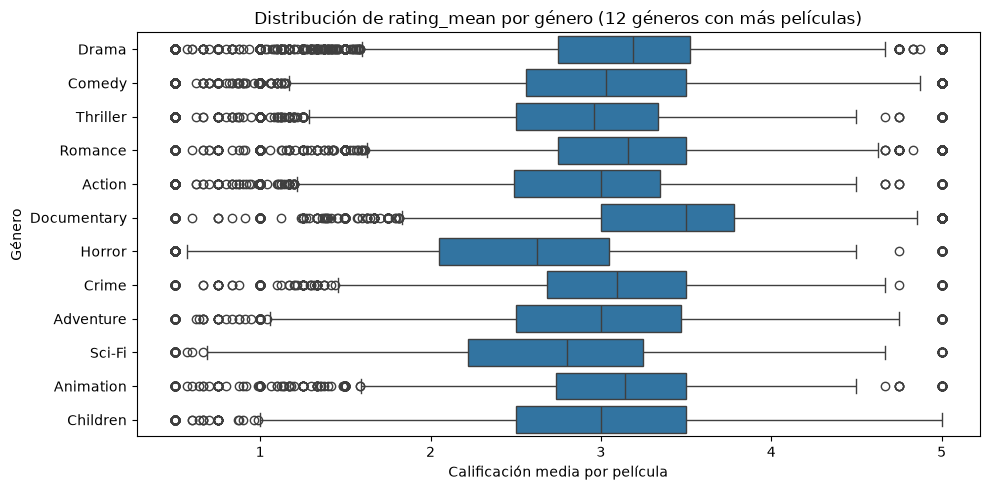

In [36]:
# ANOVA por género usando rating_mean por película
genre_counts = per_movie.groupby("genre")["rating_mean"].agg(["count", "mean", "median", "std"])
genre_counts = genre_counts.sort_values("mean", ascending=False)

eligible_genres = genre_counts.index[genre_counts["count"] >= 30].tolist()
groups = [per_movie.loc[per_movie["genre"] == g, "rating_mean"] for g in eligible_genres]

anova_f, anova_p = stats.f_oneway(*groups)
levene_stat, levene_p = stats.levene(*groups, center="median")
kruskal_h, kruskal_p = stats.kruskal(*groups)

# Eta cuadrado aproximado: variación entre géneros / variación total
all_values = pd.concat(groups)
overall_mean = all_values.mean()
ss_between = sum(len(g) * (g.mean() - overall_mean) ** 2 for g in groups)
ss_total = sum((all_values - overall_mean) ** 2)
eta_squared = ss_between / ss_total

anova_genre_results = pd.DataFrame([
    {"prueba": "ANOVA clásica", "estadístico": anova_f, "gl/grupos": f"k={len(groups)}", "p_valor": anova_p, "decisión": "Rechazar H0" if anova_p < alpha else "No rechazar H0"},
    {"prueba": "Levene (homogeneidad)", "estadístico": levene_stat, "gl/grupos": f"k={len(groups)}", "p_valor": levene_p, "decisión": "Varianzas distintas" if levene_p < alpha else "No hay evidencia de diferencias"},
    {"prueba": "Kruskal-Wallis", "estadístico": kruskal_h, "gl/grupos": f"k={len(groups)}", "p_valor": kruskal_p, "decisión": "Rechazar H0" if kruskal_p < alpha else "No rechazar H0"},
])
print("Resumen por género:")
display(genre_counts.loc[eligible_genres].head(20).round(4))
print("\nPruebas globales:")
display(anova_genre_results.round(6))
print(f"Eta cuadrado (ANOVA): {eta_squared:.4f}")

# Visualización homogénea: distribución por género (top 12 por tamaño)
top_genres = genre_counts.nlargest(12, "count").index.tolist()
plot_df = per_movie[per_movie["genre"].isin(top_genres)]
sns.boxplot(data=plot_df, x="rating_mean", y="genre", order=top_genres, orient="h")
plt.title("Distribución de rating_mean por género (12 géneros con más películas)")
plt.xlabel("Calificación media por película")
plt.ylabel("Género")
plt.tight_layout()
plt.show()


In [37]:
# Tukey HSD post hoc
if tukey_hsd is not None and anova_p < alpha:
    tukey = tukey_hsd(*groups)
    tukey_ci = tukey.confidence_interval(confidence_level=0.95)
    tukey_rows = []
    for i in range(len(eligible_genres)):
        for j in range(i + 1, len(eligible_genres)):
            tukey_rows.append({
                "género_1": eligible_genres[i],
                "género_2": eligible_genres[j],
                "diferencia_media": tukey.statistic[i, j],
                "p_valor": tukey.pvalue[i, j],
                "intervalo_95_inf": tukey_ci.low[i, j],
                "intervalo_95_sup": tukey_ci.high[i, j],
                "significativo": bool(tukey.pvalue[i, j] < alpha),
            })
    tukey_df = pd.DataFrame(tukey_rows)
    print(f"Comparaciones post hoc: {len(tukey_df):,}; significativas: {int(tukey_df['significativo'].sum())}")
    display(tukey_df.sort_values("p_valor").head(20).round(6))
else:
    tukey_df = pd.DataFrame()
    print("Tukey HSD no ejecutado: omiso si no existe scipy compatible o si ANOVA global no rechaza H0.")


Comparaciones post hoc: 171; significativas: 141


,género_1,género_2,diferencia_media,p_valor,intervalo_95_inf,intervalo_95_sup,significativo
3,Documentary,War,0.1661,0.0000,0.1026,0.2296,True
6,Documentary,Animation,0.2816,0.0000,0.2331,0.3302,True
5,Documentary,Romance,0.2493,0.0000,0.2105,0.2882,True
4,Documentary,Drama,0.2453,0.0000,0.2141,0.2765,True
7,Documentary,Crime,0.3170,0.0000,0.2738,0.3602,True
10,Documentary,Mystery,0.3971,0.0000,0.3457,0.4485,True
9,Documentary,Fantasy,0.3963,0.0000,0.3444,0.4482,True
8,Documentary,Comedy,0.3540,0.0000,0.3207,0.3874,True
12,Documentary,Children,0.4227,0.0000,0.3736,0.4718,True
13,Documentary,Western,0.4254,0.0000,0.3504,0.5004,True


#### Comparaciones post hoc: dónde aparecen las diferencias

Tukey realizó **171 comparaciones** y encontró **141 pares significativos**. Esta cantidad confirma que las diferencias no están concentradas únicamente en un par aislado.

Las diferencias más amplias permiten ilustrar el patrón:

- Documentary supera a Horror en 0.7920 puntos, con intervalo 95% [0.7515, 0.8325].
- Documentary supera a Sci-Fi en 0.6351 puntos, con intervalo [0.5872, 0.6830].
- IMAX supera a Horror en 0.6890 puntos, con intervalo [0.4946, 0.8834].
- Film-Noir supera a Thriller en 0.4829 puntos, con intervalo [0.3373, 0.6285].

Los pares anteriores muestran diferencias consistentes, porque sus intervalos quedan enteramente por encima de cero. El boxplot acompaña estos resultados al mostrar solapamientos importantes: incluso cuando las medias difieren, existe mucha variación dentro de cada género.

**Interpretación responsable.** Tukey controla el error de familia; Levene indica heterogeneidad y Kruskal-Wallis respalda el contraste no paramétrico. La pertenencia múltiple a géneros impide considerar estos 19 grupos como muestras independientes, por lo que los resultados deben interpretarse como evidencia de asociación, no como causalidad.


### 2. Películas populares vs. no populares

**Pregunta.** ¿Las películas con mayor volumen de evaluaciones reciben calificaciones medias diferentes a las demás?

**Hipótesis.** H0 afirma que las distribuciones de `rating_mean` son iguales en ambos grupos. H1 afirma que difieren.

#### Definición de los personajes comparados

Para reducir el sesgo de películas con muy pocas evaluaciones, esta prueba analiza películas con al menos **100 votos**. La popularidad se define con el percentil 75 dentro de esa muestra:

- **Popular:** `rating_count` mayor o igual a 1,845.50 evaluaciones.
- **No popular:** `rating_count` menor que 1,845.50 evaluaciones.

Esta clasificación produce 3,048 películas populares y 9,143 no populares.

#### Pruebas utilizadas

- **Mann-Whitney U:** prueba principal no paramétrica. Compara rangos y evalúa si una distribución tiende a valores mayores que la otra.
- **Welch t:** contraste complementario que compara medias sin asumir varianzas iguales entre grupos.
- **Biserial de rango aproximado:** resume la dirección de diferencia. Un valor positivo indica que el grupo popular tiende a ocupar rangos más altos.


Umbral del percentil 75: 1,845.50 evaluaciones
Resumen por popularidad:


,count,mean,median,std
popularidad,,,,
No popular,9143,3.2458,3.3182,0.4795
Popular (top 25%),3048,3.4464,3.5163,0.4477


,prueba,estadístico,p_valor,decisión
0,Mann-Whitney U,"17,374,599.0000",0.0000,Rechazar H0
1,Welch t (robustez),21.0437,0.0000,Rechazar H0


Biserial de rango aproximado: 0.2469


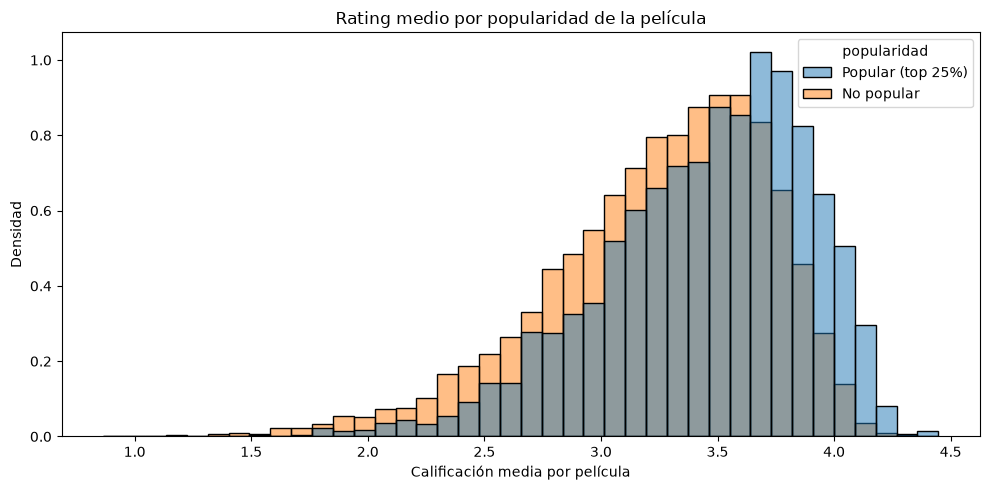

In [38]:
# Comparación popular vs no popular
rated_movies = movies[movies.rating_count >=100]\
                    .dropna(subset=["rating_mean", "rating_count"]).copy()
popular_threshold = rated_movies["rating_count"].quantile(0.75)
rated_movies["popularidad"] = np.where(
    rated_movies["rating_count"] >= popular_threshold,
    "Popular (top 25%)",
    "No popular",
)
popular = rated_movies.loc[rated_movies["popularidad"] == "Popular (top 25%)", "rating_mean"]
not_popular = rated_movies.loc[rated_movies["popularidad"] == "No popular", "rating_mean"]

mann_u, mann_p = stats.mannwhitneyu(popular, not_popular, alternative="two-sided", method="auto")
welch_t, welch_p = stats.ttest_ind(popular, not_popular, equal_var=False)
# Biserial de rango aproximado: 1 significa que popular siempre supera a no popular
rank_biserial = 2 * mann_u / (len(popular) * len(not_popular)) - 1

popularity_results = pd.DataFrame([
    {"prueba": "Mann-Whitney U", "estadístico": mann_u, "p_valor": mann_p, "decisión": "Rechazar H0" if mann_p < alpha else "No rechazar H0"},
    {"prueba": "Welch t (robustez)", "estadístico": welch_t, "p_valor": welch_p, "decisión": "Rechazar H0" if welch_p < alpha else "No rechazar H0"},
])
print(f"Umbral del percentil 75: {popular_threshold:,.2f} evaluaciones")
print("Resumen por popularidad:")
display(rated_movies.groupby("popularidad")["rating_mean"].agg(["count", "mean", "median", "std"]).round(4))
display(popularity_results.round(6))
print(f"Biserial de rango aproximado: {rank_biserial:.4f}")

sns.histplot(data=rated_movies, x="rating_mean", hue="popularidad", bins=40, stat="density", common_norm=False)
plt.title("Rating medio por popularidad de la película")
plt.xlabel("Calificación media por película")
plt.ylabel("Densidad")
plt.tight_layout()
plt.show()


#### Resultado y lectura

| Medida | No populares | Populares |
|---|---:|---:|
| n | 9,143 | 3,048 |
| Media de `rating_mean` | 3.2458 | 3.4464 |
| Mediana | 3.3182 | 3.5163 |
| Desviación estándar | 0.4795 | 0.4477 |

Las dos pruebas rechazan H0 con p-valores menores a 0.0001:

- Mann-Whitney U = 17,374,599.00.
- Welch t = 21.0437.

La popularidad se acompaña de una diferencia visible: el grupo popular presenta una media 0.2006 puntos mayor y una mediana 0.1981 puntos mayor que el grupo no popular. El biserial de rango aproximado es **0.2469**, una magnitud moderada que apoya una tendencia popular-hacia-calificaciones-más-altas.

**Interpretación y cautela.** El resultado no demuestra que ser popular haga subir la calificación. Puede haber factores comunes detrás de ambos atributos: gran expectativa, calidad percibida, antigüedad, mayor exposición o menor sesgo de selección. Además, el corte por percentil es una regla analítica y no una categoría intrínseca del catálogo.


### 3. Pruebas adicionales: ¿qué más cuenta la historia?

Además de género y popularidad, el conjunto permite investigar relaciones y diferencias con pruebas más específicas.

| Prueba | Pregunta que resuelve | Datos | Uso en este análisis |
|---|---|---|---|
| **Spearman** | ¿Votos y calificación media crecen conjuntamente de forma monotónica? | `rating_count`, `rating_mean` | La implementa sin asumir una relación lineal. |
| **Chi-cuadrado de independencia** | ¿La popularidad depende de la presencia de un género? | Género × popularidad | Se ejecuta género por género y con corrección de Bonferroni. |
| **Kruskal-Wallis o prueba de tendencia ordinal** | ¿Los rangos de calificación cambian al pasar por niveles de popularidad o antigüedad? | `rating_mean` y rangos de exposición | Complementa el contraste popular/no popular o compara más de dos bandas. |
| **Regresión ordinal o modelo mixto** | ¿Qué factores explican una calificación individual controlando usuario y película? | `rating`, `userId`, `movieId`, tiempo | Permite separar preferencias individuales de efectos de catálogo. |
| **Prueba temporal por cohortes** | ¿Cambia el patrón de calificaciones según año de estreno o periodo de evaluación? | `year` o `timestamp` | Permite estudiar deriva temporal y diferencias entre generaciones de películas. |

#### Spearman: volumen y calificación

En las **12,191 películas con al menos 100 votos**, Spearman obtuvo **rho = 0.1913** y p < 0.0001. La relación es positiva pero débil: las películas con más votos tienden a tener calificaciones medias ligeramente mayores, pero el volumen explica por sí solo una proporción pequeña de la variación.

#### Chi-cuadrado: popularidad asociada a géneros

Tras aplicar Bonferroni, aparecen asociaciones significativas para **12 géneros**: Action, Adventure, IMAX, Sci-Fi, Thriller, Documentary, Fantasy, Crime, Horror, Children, Mystery y Romance. Drama y Comedy sí tienen p-valores nominales menores que 0.05, pero dejan de ser significativos después de la corrección múltiple; Animation, Western, Musical y Film-Noir tampoco ofrecen evidencia significativa.

**Valor adicional.** Esta prueba muestra qué géneros tienen perfiles de popularidad distintos, pero no mide qué tan grande es esa asociación ni establece qué género “produce” popularidad.


In [39]:
# Prueba adicional: Spearman entre volumen de votos y rating medio
spearman_df = rated_movies[rated_movies["rating_count"] >= 100]
spearman_r, spearman_p = stats.spearmanr(
    spearman_df["rating_count"],
    spearman_df["rating_mean"],
)
print("Spearman formal (películas con al menos 100 votos):")
display(pd.DataFrame([{
    "prueba": "Spearman",
    "n": len(spearman_df),
    "rho": spearman_r,
    "p_valor": spearman_p,
    "decisión": "Rechazar H0" if spearman_p < alpha else "No rechazar H0",
}]).round(6))


Spearman formal (películas con al menos 100 votos):


,prueba,n,rho,p_valor,decisión
0,Spearman,12191,0.1913,0.0000,Rechazar H0


In [40]:
# Prueba adicional: chi-cuadrado popularidad × género
# Se evalúa género por género; 0.05/20 usa una aproximación conservadora de Bonferroni.
top_genres_for_test = genre_counts.nlargest(20, "count").index.tolist()
chi_rows = []
for genre_name in top_genres_for_test:
    presence = per_movie.drop_duplicates("movieId").merge(
        movie_genres[movie_genres["genre"] == genre_name][["movieId"]].assign(presencia=1),
        on="movieId",
        how="left",
    )
    presence["presencia"] = presence["presencia"].fillna(0)
    presence = presence.merge(rated_movies[["movieId", "popularidad"]], on="movieId", how="inner")
    contingency = pd.crosstab(presence["presencia"], presence["popularidad"])
    if contingency.shape == (2, 2):
        chi2, pvalue, dof, expected = stats.chi2_contingency(contingency, correction=False)
        chi_rows.append({
            "género": genre_name,
            "chi2": chi2,
            "gl": dof,
            "p_valor": pvalue,
            "p_bonferroni": min(1.0, pvalue * len(top_genres_for_test)),
            "significativo_bonferroni": pvalue * len(top_genres_for_test) < alpha,
        })

chi_df = pd.DataFrame(chi_rows)
print("Chi-cuadrado por género (popular vs no popular):")
display(chi_df.sort_values("p_bonferroni").round(6))


Chi-cuadrado por género (popular vs no popular):


,género,chi2,gl,p_valor,p_bonferroni,significativo_bonferroni
4,Action,286.4804,1,0.0000,0.0000,True
8,Adventure,232.3208,1,0.0000,0.0000,True
18,IMAX,210.7709,1,0.0000,0.0000,True
9,Sci-Fi,165.6011,1,0.0000,0.0000,True
2,Thriller,100.4837,1,0.0000,0.0000,True
5,Documentary,91.6613,1,0.0000,0.0000,True
13,Fantasy,57.0197,1,0.0000,0.0000,True
7,Crime,35.4864,1,0.0000,0.0000,True
6,Horror,21.8415,1,0.0000,0.0001,True
11,Children,20.5755,1,0.0000,0.0001,True


### 4. Conclusión integrada

La evidencia converge en un patrón: **las calificaciones medias no son homogéneas entre géneros ni entre niveles de popularidad**. Las mayores medias aparecen en Documentaries, Film-Noir e IMAX; las menores, en Horror, Sci-Fi y Action. Al comparar títulos populares y no populares, los populares promedian 3.4464 frente a 3.2458 y mantienen una mediana mayor.

El siguiente nivel de detalle viene de las comparaciones por pares y asociaciones adicionales:

- Tukey encuentra 141 pares significativos entre 171 posibles.
- Mann-Whitney y Welch coinciden en rechazar la igualdad entre popularidad.
- Spearman revela una relación positiva débil entre votos y calificación (`rho = 0.1913`).
- Chi-cuadrado muestra 12 géneros asociados significativamente con popularidad después de Bonferroni.

La lectura definitiva debe ser moderada. En bases de gran tamaño, la significancia es fácil de alcanzar; por eso se integran las medias, medianas, intervalos, proporción de variación y efectos de rango. Además, un género puede solaparse con otros, una calificación media puede ocultar diferencias entre usuarios y popularidad puede reflejar exposición en lugar de calidad. Las pruebas implementadas describen diferencias y asociaciones observables, pero no prueban causalidad.
